# How clean is New York City's air, and who pays for what's left?

An analysis of the NYC Community Air Survey, 2009–2024, in four questions:

1. **Trend:** how much cleaner has the air become?
2. **2023 smoke:** how far did the wildfire summer break from that trend, and did it reach every neighborhood?
3. **Sources:** what local activity tracks a neighborhood's pollution level?
4. **Burden:** do the most polluted neighborhoods carry the most health harm?

All the logic lives in `src/nyc_air/`; this notebook walks through it. `python scripts/run_analysis.py` produces the same figures and numbers without opening Jupyter.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from nyc_air import analysis, data, plots

pd.set_option("display.precision", 2)
plots.use_style()

df = data.load_air_quality()
hoods = data.load_neighborhoods()
ids = data.neighborhood_ids(df)
print(f"{len(df):,} rows, {df['indicator'].nunique()} indicators, years {df['year'].min()}–{df['year'].max()}")

19,827 rows, 18 indicators, years 2005–2024


## The data has one trap

Every indicator is published at five geography levels at once. Mixing levels in a single table (a borough next to the neighborhoods inside it) double-counts the same air and distorts correlations. Everything below picks **one** level: citywide for trends, the 42 UHF neighborhoods for comparing places.

In [2]:
(df[df["indicator"] == data.PM25]
   .groupby("geo_type")["place"].nunique()
   .rename("places per level (PM2.5)")
   .to_frame())

,places per level (PM2.5)
geo_type,
Borough,5
CD,59
Citywide,1
UHF34,34
UHF42,42


## 1. The long-term trend

Citywide annual PM2.5 (fine particles, the pollutant most tied to heart and lung disease) and NO2 (mostly from combustion), plus summer ozone.

In [3]:
t = analysis.trend(df)
pd.DataFrame({"PM2.5 annual (µg/m³)": t["pm25"], "NO2 annual (ppb)": t["no2"],
              "Ozone summer (ppb)": t["ozone"]}).loc[[2009, 2014, 2019, 2022, 2023, 2024]]

,PM2.5 annual (µg/m³),NO2 annual (ppb),Ozone summer (ppb)
year,,,
2009,10.43,22.72,26.00
2014,8.93,18.89,31.37
2019,6.60,15.59,30.55
2022,5.76,14.73,34.08
2023,6.66,15.51,35.54
2024,6.26,14.11,33.99


In [4]:
print(f"PM2.5: {t['pm25_first']:.1f} in {t['first_year']} -> {t['pm25_low']:.1f} in {t['pm25_low_year']} "
      f"({t['pm25_drop_to_low_pct']:.0f}%); {t['pm25_last']:.1f} in {t['last_year']}")
print(f"NO2:   {t['no2_first']:.1f} -> {t['no2_last']:.1f} ppb ({t['no2_drop_pct']:.0f}%)")
print(f"Ozone (summer): {t['ozone_2010']:.1f} in 2010 -> {t['ozone_last']:.1f} in {t['last_year']}: no improvement")

PM2.5: 10.4 in 2009 -> 5.8 in 2022 (-45%); 6.3 in 2024
NO2:   22.7 -> 14.1 ppb (-38%)
Ozone (summer): 33.7 in 2010 -> 34.0 in 2024: no improvement


PM2.5 and NO2 both fell by roughly 40%. Ozone did not. (2009 is left out as its starting point because that summer's ozone, 26 ppb, was an outlier well below every later year.) Ozone forms from other pollutants in sunlight and heat, so cutting local combustion helps it less.

## 2. The 2023 smoke season

In June 2023, smoke from Canadian wildfires blanketed the city. The dataset reports seasonal averages, not daily readings, so the question is whether the *whole summer* stands out. The benchmark is a straight-line fit to summers 2009–2022.

In [5]:
s = analysis.smoke_2023(df)
print(f"Expected summer 2023 from the trend: {s['expected']:.2f} µg/m³")
print(f"Actual summer 2023:                  {s['actual']:.2f} µg/m³ ({s['above_trend_pct']:+.0f}% vs trend)")
print(f"Highest summer average since {s['highest_summer_since']}")
print(f"Neighborhoods worse than summer 2022: {s['n_rose']} of {s['n_neighborhoods']} "
      f"(+{s['change_min']:.0f}% to +{s['change_max']:.0f}%, median +{s['change_median']:.0f}%)")

Expected summer 2023 from the trend: 6.46 µg/m³
Actual summer 2023:                  8.81 µg/m³ (+36% vs trend)
Highest summer average since 2017
Neighborhoods worse than summer 2022: 42 of 42 (+17% to +47%, median +33%)


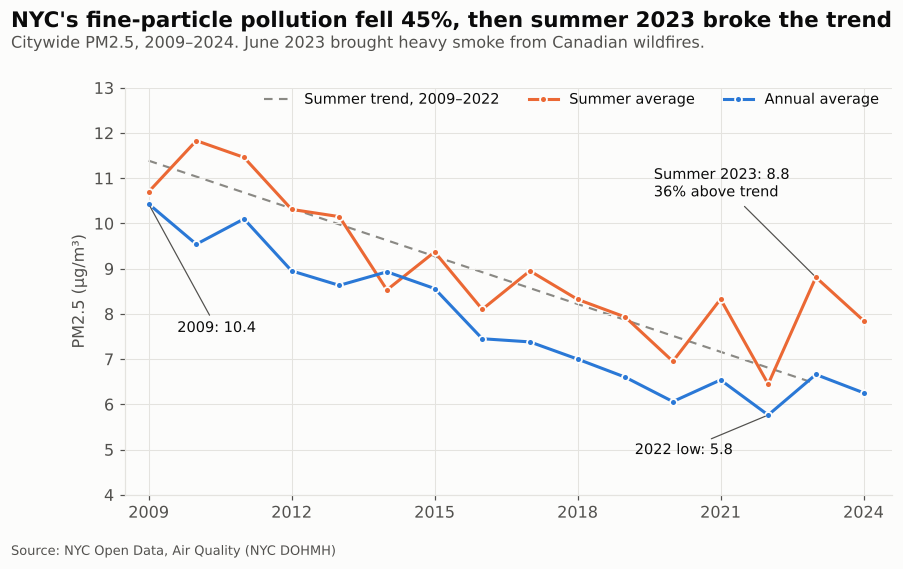

In [6]:
fig = plots.trend_chart(t, s)

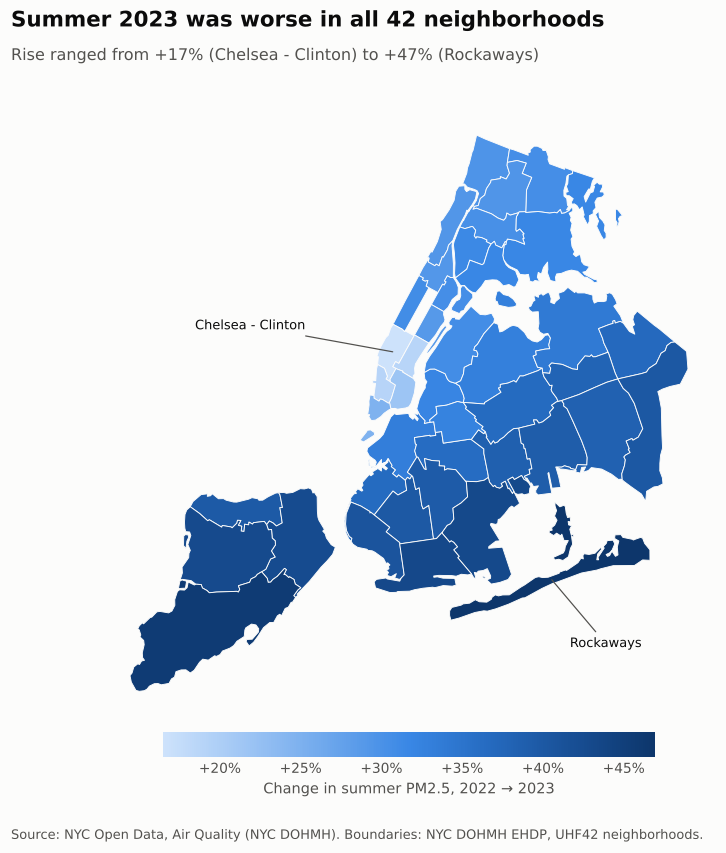

In [7]:
fig = plots.smoke_map(s, hoods, ids)

Every neighborhood got worse, but not equally. The rise was largest on the city's southern edges (the Rockaways, Staten Island, south Brooklyn), about +2.6 µg/m³, and smallest in Midtown Manhattan, about +1.4 µg/m³. Seasonal averages can't say why; daily data on smoke plumes would be needed to explain the pattern.

## 3. Sources

For 2019, the latest year with both traffic and building-boiler data, correlate each source with neighborhood PM2.5 and NO2.

In [8]:
src = analysis.sources(df)
src["table"].pivot(index="source", columns="pollutant", values="r").round(2)

pollutant,NO2,PM2.5
source,,
Building boilers (NOx),0.82,0.79
Building boilers (PM2.5),0.82,0.79
Traffic (all vehicles),0.81,0.75
Traffic (cars),0.79,0.73
Traffic (trucks),0.72,0.74


Traffic density vs boiler emissions across neighborhoods: r = 0.80


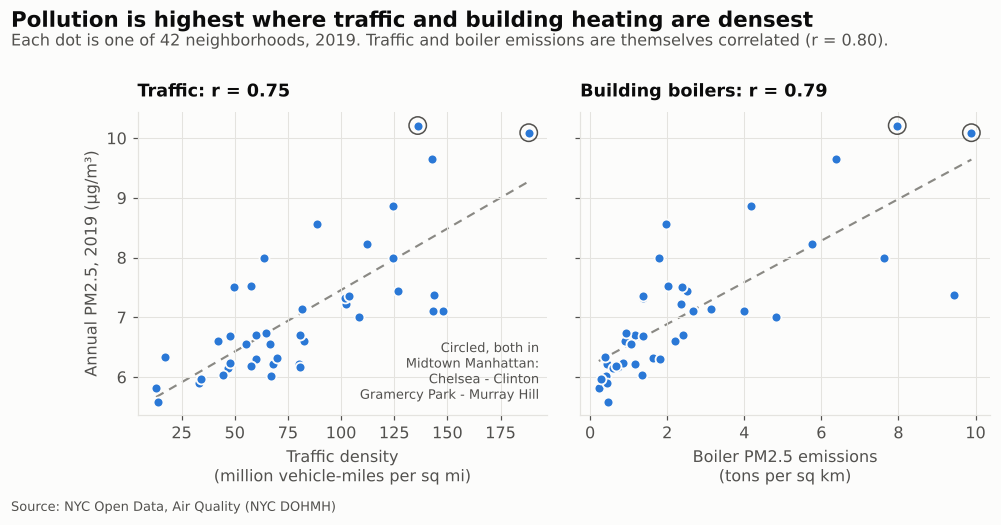

In [9]:
print(f"Traffic density vs boiler emissions across neighborhoods: r = {src['traffic_vs_boilers_r']:.2f}")
fig = plots.sources_chart(src)

Both sources track pollution closely (r = 0.75–0.79 for PM2.5). They also track *each other* (r = 0.80): the neighborhoods with the most traffic are the same dense neighborhoods with the most buildings burning fuel for heat. With 42 neighborhoods, the data cannot say how much each source contributes on its own. The defensible finding is that pollution concentrates where both are densest, which in NYC means Midtown Manhattan.

## 4. Burden

The city estimates how many ER visits, hospitalizations, and deaths are caused by PM2.5 in each neighborhood. Compare those estimates (2017–2019) with exposure over the same years.

In [10]:
b = analysis.burden(df)
print(f"PM2.5 ranges {b['exposure_ratio']:.1f}x across neighborhoods")
print(f"PM2.5-caused child asthma ER visits range {b['child_ed_ratio']:.0f}x")
c = b["pm_vs_child_ed"]
print(f"Correlation between the two: r = {c['r']:.2f} (p = {c['p']:.2f}), i.e. none")
b["top_child_ed"].rename(columns={"pm25": "PM2.5 (µg/m³)",
                                  "child_asthma_ed": "Child asthma ER visits per 100k",
                                  "deaths": "Deaths per 100k (age 30+)"})

PM2.5 ranges 1.7x across neighborhoods
PM2.5-caused child asthma ER visits range 16x
Correlation between the two: r = 0.06 (p = 0.73), i.e. none


,PM2.5 (µg/m³),Child asthma ER visits per 100k,Deaths per 100k (age 30+)
place,,,
East Harlem,7.54,160.0,45.0
Hunts Point - Mott Haven,7.88,147.0,39.0
Central Harlem - Morningside Heights,7.49,138.0,38.0
High Bridge - Morrisania,7.66,138.0,37.0
Crotona - Tremont,7.64,119.0,34.0


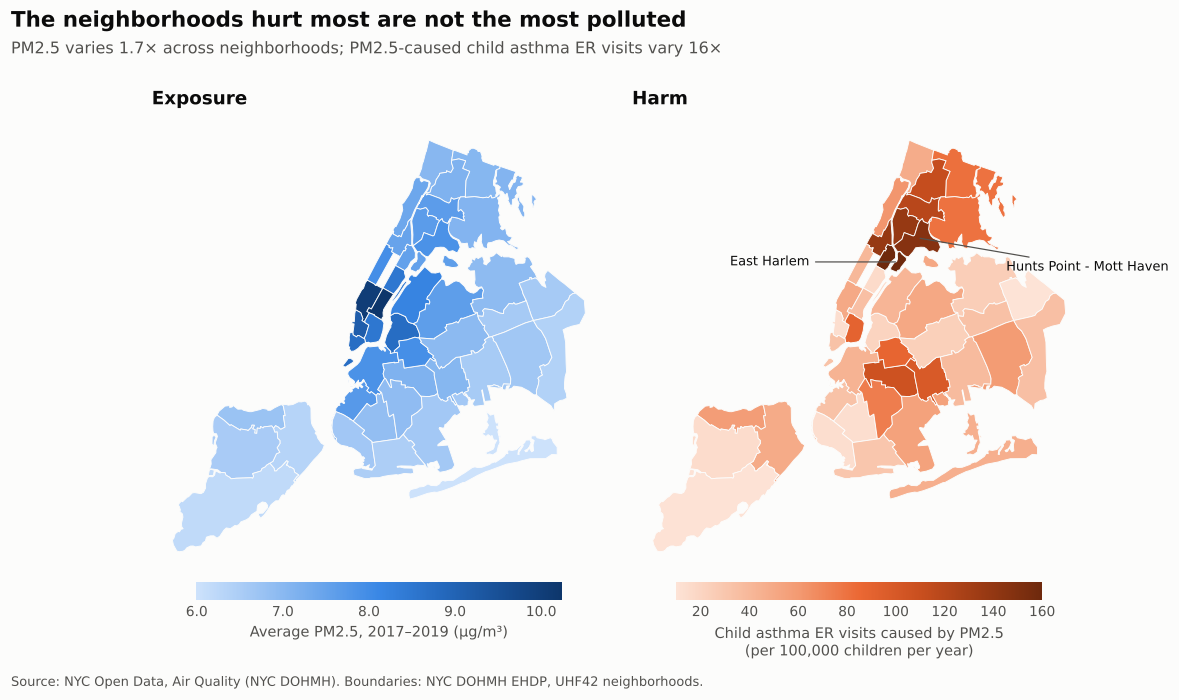

In [11]:
fig = plots.burden_maps(b, hoods, ids)

The most polluted air is in Midtown Manhattan. The most harm from that pollution falls on East Harlem, the South Bronx, and central Brooklyn, which breathe only moderately polluted air. The city's estimates combine exposure with how common asthma already is in each neighborhood, so the same air does far more damage where children are already sick more often. Pollution levels alone are a poor guide to where cleaner air would help most.

## Limitations

- **Correlation, not cause.** Neighborhood comparisons cannot separate traffic from building emissions, and other differences between neighborhoods are not controlled for.
- **Seasonal averages.** Summer means smooth over the worst smoke days, so the 2023 figures understate the peak.
- **Modeled values.** Pollution levels are model estimates from a monitoring network; health figures are the city's attributable-impact estimates, not observed cases.
- **Different years for different indicators.** Sources are compared for 2019 and health for 2017–2019, the latest years each is available.